# 02 · SHAP comparison: XGBoost vs multivariable linear regression

Produces **Supplementary Figure 3**: SHAP summary plots for XGBoost (A) and for a linear regression
(B) fitted on the same 17 predictors, target transformation, measurements and training/test split,
and SHAP dependence plots for iron dose and serum ferritin (C–F).

Linear regression cannot use missing values, so its missing predictor values are replaced by the
training-set median; XGBoost uses its native handling of missing values on the same measurements.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
FINAL_PARAMS = {"colsample_bytree": 0.7, "learning_rate": 0.05, "max_depth": 8, "n_estimators": 400, "subsample": 0.8}
FEATURES = ["Age (y)", "Isotope", "Meal type", "Fe compound", "Fe dose", "Vitamin C dose",
                "Calcium dose", "Zinc dose ", "Polyphenol dose", "Phytic acid dose",
                "C-reactive protein", "Hep", "Ferritin", "Hb", "BMI", "BV", "Fe.circ"]
os.makedirs("../figures/panels", exist_ok=True)

## 1. Data (same measurements and split as notebook 01)

In [2]:
raw = pd.read_excel("../data/pooled_dataset.xls")
d = raw.copy()
d["Meal type"] = d["Meal type"].fillna("Supplement")
d["Isotope"] = d["Isotope"].fillna("Unknown")
for col in FEATURES:
    if d[col].dtype == object:
        d[col] = d[col].astype("category").cat.codes
d = d[d[FEATURES + ["Fe absorption (%)"]].isnull().sum(axis=1) < 14]

y = np.log10(d["Fe absorption (%)"] + 1)
X = d[FEATURES]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Training:", len(X_train), "| held-out test:", len(X_test))

Training: 4046 | held-out test: 1012


## 2. Models

In [3]:
imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

linreg = LinearRegression().fit(X_train_imp, y_train)

xgb_model = xgb.XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS)
xgb_model.fit(X_train, y_train)

shap_lin = shap.LinearExplainer(linreg, X_train_imp).shap_values(X_test_imp)
shap_xgb = shap.TreeExplainer(xgb_model).shap_values(X_test)

## 3. Supplementary Figure 3A–B: SHAP summary plots

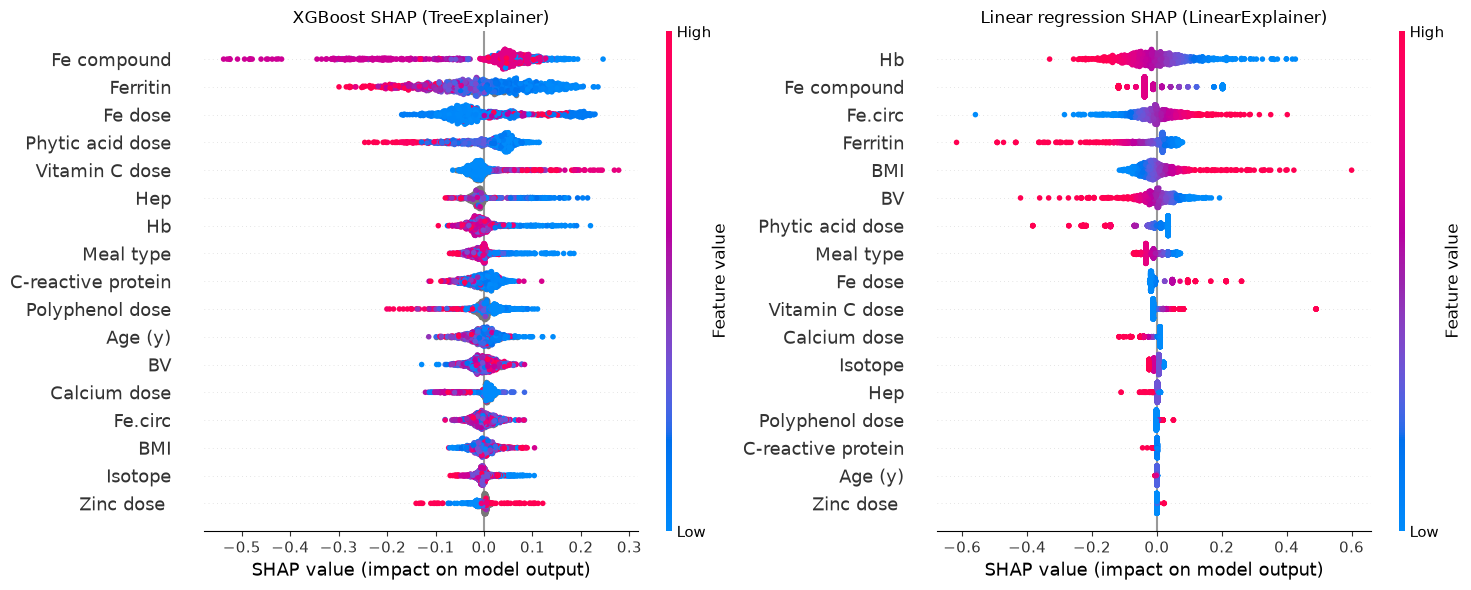

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plt.sca(axes[0])
shap.summary_plot(shap_xgb, X_test, show=False, plot_size=None)
axes[0].set_title("XGBoost SHAP (TreeExplainer)")
plt.sca(axes[1])
shap.summary_plot(shap_lin, X_test_imp, show=False, plot_size=None)
axes[1].set_title("Linear regression SHAP (LinearExplainer)")
plt.tight_layout()
plt.savefig("../figures/panels/SuppFig3AB.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Supplementary Figure 3C–F: SHAP dependence plots for iron dose and serum ferritin

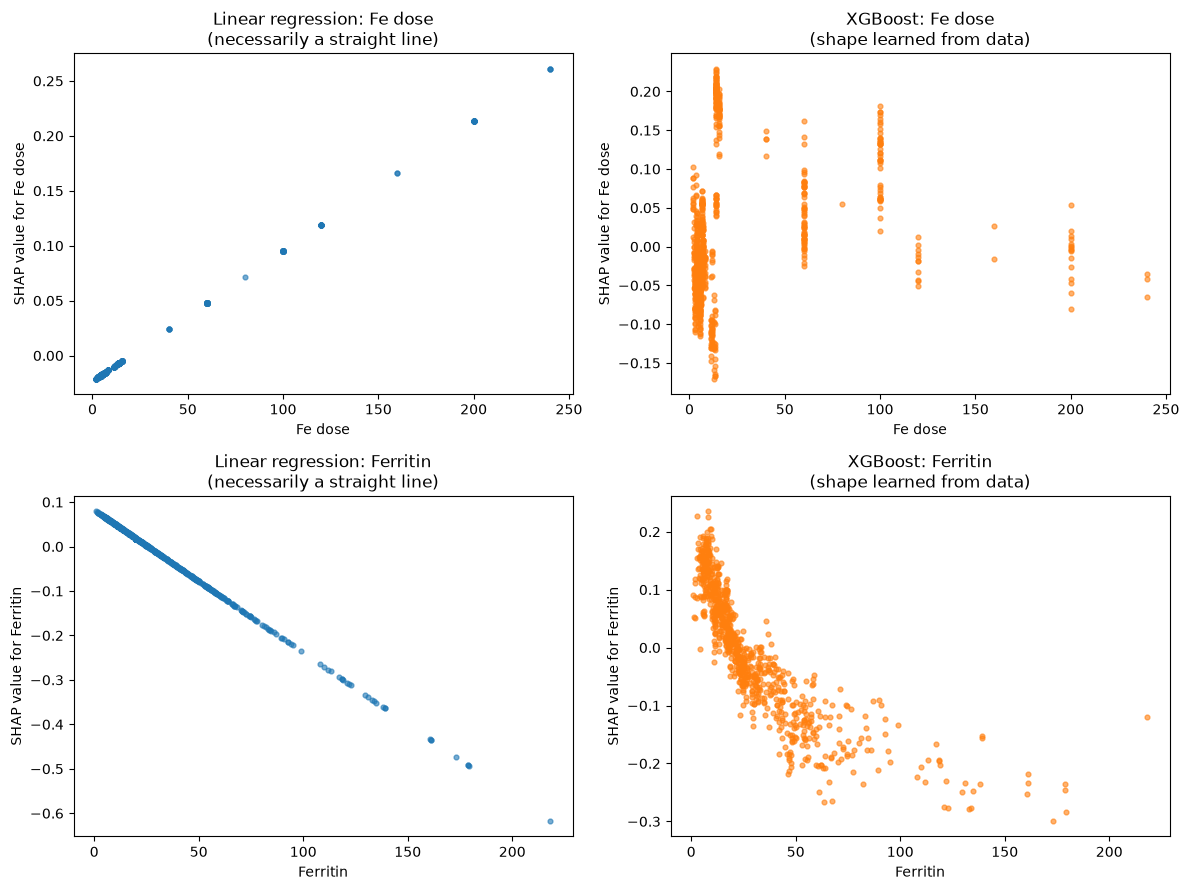

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, feature in enumerate(["Fe dose", "Ferritin"]):
    fi = list(X.columns).index(feature)
    axes[row, 0].scatter(X_test_imp[feature], shap_lin[:, fi], s=12, alpha=0.6, color="tab:blue")
    axes[row, 0].set_xlabel(feature)
    axes[row, 0].set_ylabel(f"SHAP value for {feature}")
    axes[row, 0].set_title(f"Linear regression: {feature}\n(necessarily a straight line)")
    axes[row, 1].scatter(X_test[feature], shap_xgb[:, fi], s=12, alpha=0.6, color="tab:orange")
    axes[row, 1].set_xlabel(feature)
    axes[row, 1].set_ylabel(f"SHAP value for {feature}")
    axes[row, 1].set_title(f"XGBoost: {feature}\n(shape learned from data)")
plt.tight_layout()
plt.savefig("../figures/panels/SuppFig3CF.png", dpi=150, bbox_inches="tight")
plt.show()